# 🌲 Classical ML on Raw 3D Seismic Signal
## Animal Footstep Binary Classification — Elephant vs Wildebeest | scikit-learn Benchmark

**Approach:** Instead of a graph neural network, we extract a fixed-length
**hand-crafted feature vector** from each raw 3D seismic recording and classify it
with classical machine-learning models (Random Forest, Gradient Boosting, SVM, …).

**Why a classical-ML benchmark is included:**
- Extremely lightweight and trivially edge-deployable (no GPU, tiny model)
- Strong, interpretable baseline (feature importances) for the GNN/ANN study
- No deep-learning dependencies — only `numpy`, `scipy`, `scikit-learn`

**Dataset variables (from `dset_allspec_150_chunks_clean.nc`):**
- `chunk(traces, comp, time)` → Raw seismic signal, shape `(N, 3, 2048)` — **this is our input**
- `class(traces)` → Animal class label
- `distance(traces)` → Distance from sensor to animal
- `image(traces, side, side, comp)` → Pre-computed spectrograms (we **do NOT use these**)
- `seis(traces)` → Seismic event ID


---
## 🔧 CELL 1: Setup & Configuration


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from scipy.signal import find_peaks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

SEED = 42
np.random.seed(SEED)
print('scikit-learn classical-ML pipeline')
print('Setup complete ✓')


scikit-learn classical-ML pipeline
Setup complete ✓


---
## 📂 CELL 2: Load Dataset & Inspect Structure


In [2]:
import netCDF4 as nc

CANDIDATES = [
    'dset_allspec_150_chunks_clean.nc',
    'PROJECT/dset_allspec_150_chunks_clean.nc',
    '/Users/aaronr/Desktop/DUK/PROJECT/SIGNAL_ PROCESSING_PROJECT/dset_allspec_150_chunks_clean.nc',
]
FILE_PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])

dataset = nc.Dataset(FILE_PATH, mode='r')
print('=' * 60); print('Dataset Summary'); print('=' * 60)
print('Variables:', list(dataset.variables.keys()))
for v in dataset.variables.keys():
    print(f'  {v:12s}: shape = {dataset.variables[v].shape}, dtype = {dataset.variables[v].dtype}')

all_labels = dataset['class'][:].astype(int)
uniq, cnt = np.unique(all_labels, return_counts=True)
print(f'\nTotal recordings : {len(all_labels)}')
for cls, c in zip(uniq, cnt):
    print(f'  Class {cls:3d}: {c:6d} samples')


Dataset Summary
Variables: ['chunk', 'class', 'distance', 'seis', 'image']
  chunk       : shape = (70637, 3, 2048), dtype = float32
  class       : shape = (70637,), dtype = int64
  distance    : shape = (70637,), dtype = float32
  seis        : shape = (70637,), dtype = int64
  image       : shape = (70637, 128, 128, 3), dtype = int64

Total recordings : 70637
  Class   0:   2073 samples
  Class   1:  62493 samples
  Class   2:    164 samples
  Class   3:      2 samples
  Class   4:    271 samples
  Class   5:    769 samples
  Class   6:   4321 samples
  Class   7:     42 samples
  Class   8:     10 samples
  Class   9:    488 samples
  Class  11:      4 samples


---
## 🗺️ CELL 3: Select Classes & Load Raw Signal Data


In [3]:
SPECIES_NAMES = {0:'Human',1:'Elephant',2:'Giraffe',3:'Lion',4:'Buffalo',
                 5:'Zebra',6:'Wildebeest',7:'Hippo',8:'Cheetah',9:'Hyena'}
SELECTED_CLASSES = [1, 6]   # Elephant vs Wildebeest (2-class binary)

mask = np.isin(all_labels, SELECTED_CLASSES)
chunks = dataset['chunk'][:][mask]          # (N, 3, 2048) raw 3D signal
labels = all_labels[mask]
dataset.close()

label_map = {c: i for i, c in enumerate(sorted(SELECTED_CLASSES))}   # {1:0, 6:1}
y = np.array([label_map[l] for l in labels])
label_names = [SPECIES_NAMES[c] for c in sorted(SELECTED_CLASSES)]

u, c = np.unique(y, return_counts=True)
print(f'Using classes {label_names}, {len(y)} samples total')
for ui, ci in zip(u, c):
    print(f'  {label_names[ui]:12s}: {ci:6d}')
print(f'Imbalance ratio ~ {c.max()/c.min():.1f} : 1  (minority = {label_names[int(np.argmin(c))]})')


Using classes ['Elephant', 'Wildebeest'], 66814 samples total
  Elephant    :  62493
  Wildebeest  :   4321
Imbalance ratio ~ 14.5 : 1  (minority = Wildebeest)


---
## 🏔️ CELL 4: Peak Detection Visualisation


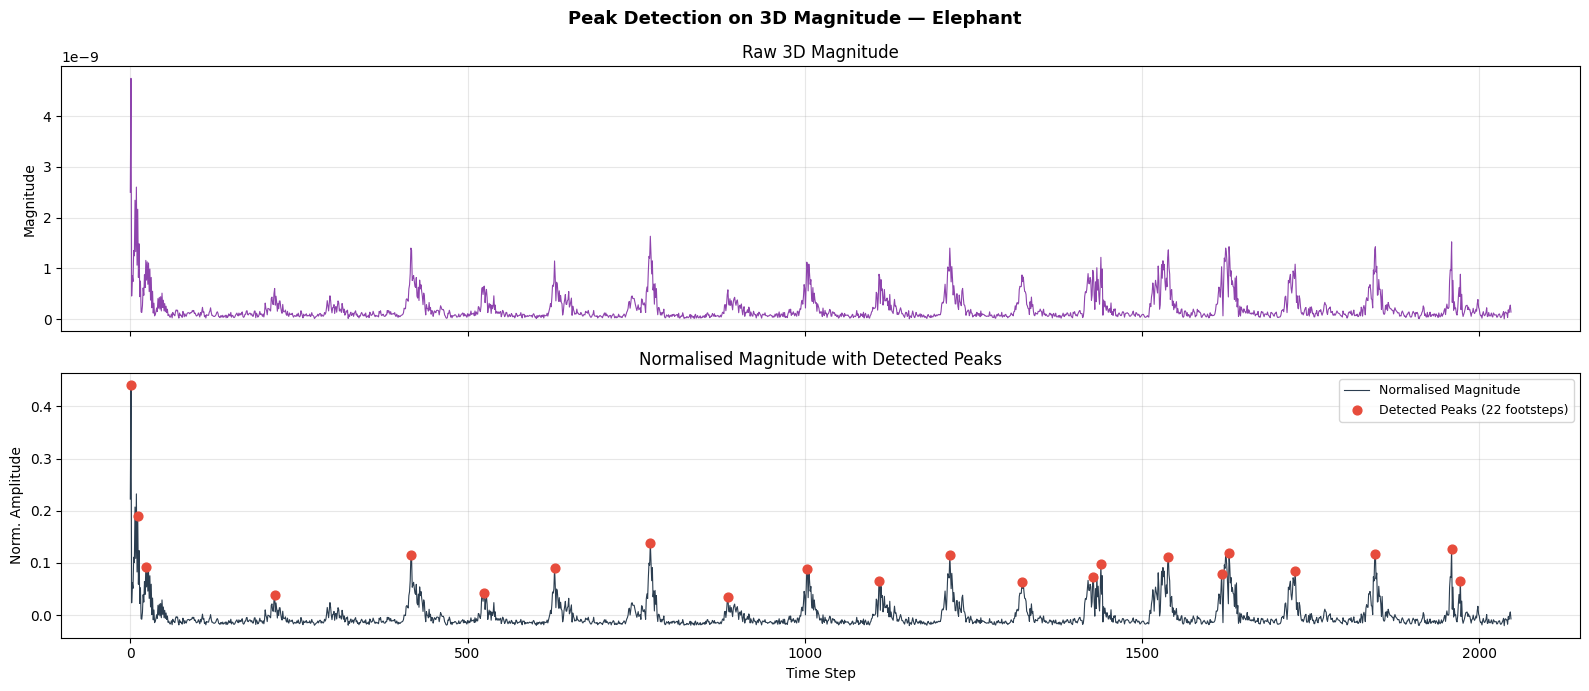

Detected 22 footstep peaks — summarised into features in the next cell.


In [4]:
def compute_magnitude(sig3d):
    return np.sqrt(sig3d[0]**2 + sig3d[1]**2 + sig3d[2]**2)

raw = chunks[0]; mag = compute_magnitude(raw)
mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
peaks, props = find_peaks(mag_norm, prominence=0.05, distance=10)
t = np.arange(len(mag_norm))

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
fig.suptitle(f'Peak Detection on 3D Magnitude — {SPECIES_NAMES.get(int(labels[0]), "?")}',
             fontsize=13, fontweight='bold')
axes[0].plot(t, mag, color='#8e44ad', linewidth=0.8)
axes[0].set_title('Raw 3D Magnitude'); axes[0].set_ylabel('Magnitude'); axes[0].grid(True, alpha=0.3)
axes[1].plot(t, mag_norm, color='#2c3e50', linewidth=0.8, label='Normalised Magnitude')
axes[1].scatter(peaks, mag_norm[peaks], color='#e74c3c', zorder=5, s=40,
                label=f'Detected Peaks ({len(peaks)} footsteps)')
axes[1].set_title('Normalised Magnitude with Detected Peaks')
axes[1].set_ylabel('Norm. Amplitude'); axes[1].set_xlabel('Time Step')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ml_peak_detection_demo.png', dpi=150, bbox_inches='tight'); plt.show()
print(f'Detected {len(peaks)} footstep peaks — summarised into features in the next cell.')


---
## 🧮 CELL 5: Feature Engineering

Each recording → a fixed **29-D feature vector** (independent of how many footsteps
it contains), combining global time-domain statistics with footstep-peak statistics
from the 3D magnitude envelope:
- **Per-axis (X, Y, Z):** mean, std, max, abs-max, energy, zero-crossing rate
- **3D magnitude:** mean, std, max, energy
- **Footstep peaks:** count, mean/std/max height, mean prominence, mean inter-peak gap


In [5]:
FEATURE_NAMES = (
    [f'{ax}_{s}' for ax in ['X','Y','Z'] for s in ['mean','std','max','absmax','energy','zcr']]
    + ['mag_mean','mag_std','mag_max','mag_energy',
       'n_peaks','peak_mean_h','peak_std_h','peak_mean_prom','peak_mean_gap','peak_max_h']
)

def extract_features(sig3d, prominence=0.05, distance=10):
    feats = []
    for ax in range(3):                       # per-axis time-domain stats
        s = sig3d[ax]
        zcr = np.mean(np.abs(np.diff(np.sign(s)))) / 2.0
        feats += [s.mean(), s.std(), s.max(), np.abs(s).max(), float(np.sum(s**2)), zcr]
    mag = np.sqrt(sig3d[0]**2 + sig3d[1]**2 + sig3d[2]**2)   # 3D magnitude envelope
    feats += [mag.mean(), mag.std(), mag.max(), float(np.sum(mag**2))]
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)        # footstep peak stats
    peaks, props = find_peaks(mag_norm, prominence=prominence, distance=distance)
    if len(peaks) > 0:
        heights, proms = mag[peaks], props['prominences']
        gaps = np.diff(peaks) if len(peaks) > 1 else np.array([0.0])
        feats += [len(peaks), heights.mean(), heights.std(),
                  proms.mean(), gaps.mean(), heights.max()]
    else:
        feats += [0, 0, 0, 0, 0, 0]
    return np.array(feats, dtype=np.float32)

from tqdm import tqdm
X = np.stack([extract_features(chunks[i]) for i in tqdm(range(len(chunks)), desc='features')])
X = np.nan_to_num(X)
print(f'Feature matrix: {X.shape}  ({len(FEATURE_NAMES)} features/recording)')


features: 100%|██████████| 66814/66814 [00:57<00:00, 1152.31it/s]

Feature matrix: (66814, 28)  (28 features/recording)


---
## 🏗️ CELL 6: Train/Test Split & Scaling


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print(f'Train: {X_train.shape[0]}   Test: {X_test.shape[0]}')
print('Scaling applied (linear/distance models use scaled features; trees use raw).')


Train: 53451   Test: 13363
Scaling applied (linear/distance models use scaled features; trees use raw).


---
## 🧠 CELL 7: Candidate ML Models

All models use class balancing to counter the imbalance:
`class_weight='balanced'` where supported, else balanced sample weights /
`scale_pos_weight`.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

MODELS = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'SVM (RBF)':          SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=SEED),
    'kNN':                KNeighborsClassifier(n_neighbors=7),
    'RandomForest':       RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                 random_state=SEED, n_jobs=-1),
    'GradientBoosting':   GradientBoostingClassifier(n_estimators=200, random_state=SEED),
}
try:
    from xgboost import XGBClassifier
    spw = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
    MODELS['XGBoost'] = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                      scale_pos_weight=spw, eval_metric='logloss',
                                      random_state=SEED, n_jobs=-1)
    print('XGBoost available ✓')
except Exception:
    print('XGBoost not installed; skipping (optional).')

NEEDS_SCALING = {'LogisticRegression', 'SVM (RBF)', 'kNN'}
print(f'{len(MODELS)} candidate models ready.')


XGBoost available ✓
6 candidate models ready.


---
## 🏋️ CELL 8: Train & Compare All Models


In [8]:
results, fitted = [], {}
for name, model in MODELS.items():
    Xtr = X_train_s if name in NEEDS_SCALING else X_train
    Xte = X_test_s  if name in NEEDS_SCALING else X_test
    if name == 'GradientBoosting':
        model.fit(Xtr, y_train, sample_weight=compute_sample_weight('balanced', y_train))
    else:
        model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    results.append({'model': name,
                    'accuracy': accuracy_score(y_test, pred),
                    'macro_f1': f1_score(y_test, pred, average='macro'),
                    'weighted_f1': f1_score(y_test, pred, average='weighted'),
                    f'{label_names[1]}_f1': f1_score(y_test, pred, average=None)[1]})
    fitted[name] = model
    print(f'{name:20s}  acc {results[-1]["accuracy"]:.4f}  '
          f'macroF1 {results[-1]["macro_f1"]:.4f}  '
          f'{label_names[1]}-F1 {results[-1][f"{label_names[1]}_f1"]:.4f}')

tbl = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
for col in tbl.columns:
    if col != 'model': tbl[col] = tbl[col].round(4)
print('\n🏆 MODEL COMPARISON (sorted by macro-F1):')
print(tbl.to_string(index=False))


LogisticRegression    acc 0.7056  macroF1 0.5134  Wildebeest-F1 0.2075
SVM (RBF)             acc 0.7816  macroF1 0.5713  Wildebeest-F1 0.2712
kNN                   acc 0.9511  macroF1 0.7274  Wildebeest-F1 0.4805
RandomForest          acc 0.9254  macroF1 0.6726  Wildebeest-F1 0.3849
GradientBoosting      acc 0.7299  macroF1 0.5505  Wildebeest-F1 0.2666
XGBoost               acc 0.9248  macroF1 0.7754  Wildebeest-F1 0.5923

🏆 MODEL COMPARISON (sorted by macro-F1):
             model  accuracy  macro_f1  weighted_f1  Wildebeest_f1
           XGBoost    0.9248    0.7754       0.9349         0.5923
               kNN    0.9511    0.7274       0.9424         0.4805
      RandomForest    0.9254    0.6726       0.9231         0.3849
         SVM (RBF)    0.7816    0.5713       0.8327         0.2712
  GradientBoosting    0.7299    0.5505       0.7977         0.2666
LogisticRegression    0.7056    0.5134       0.7797         0.2075


---
## 📈 CELL 9: Comparison Chart


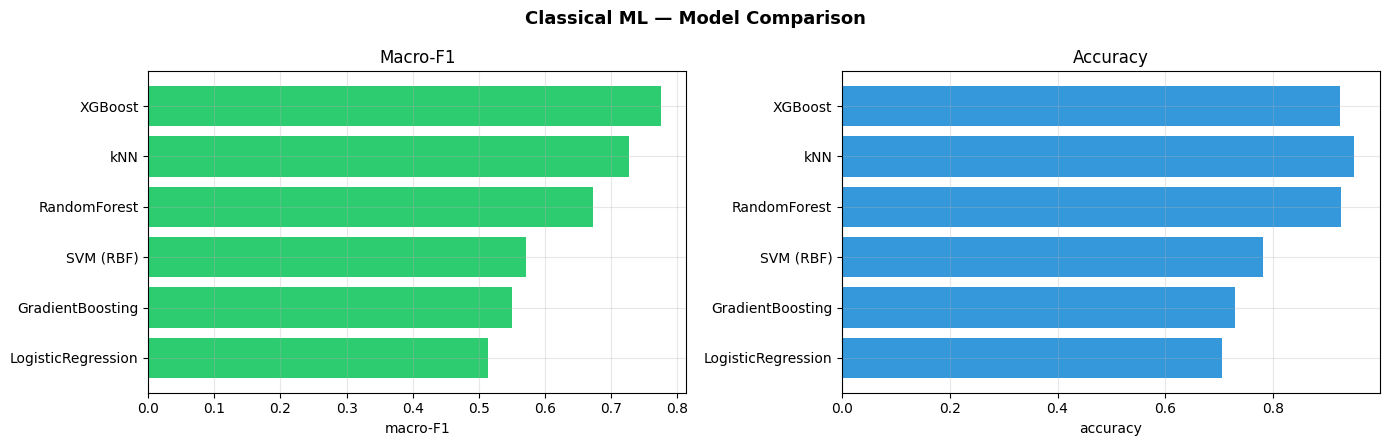

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
fig.suptitle('Classical ML — Model Comparison', fontsize=13, fontweight='bold')
ax[0].barh(tbl['model'], tbl['macro_f1'], color='#2ecc71'); ax[0].set_xlabel('macro-F1')
ax[0].set_title('Macro-F1'); ax[0].invert_yaxis(); ax[0].grid(True, alpha=0.3)
ax[1].barh(tbl['model'], tbl['accuracy'], color='#3498db'); ax[1].set_xlabel('accuracy')
ax[1].set_title('Accuracy'); ax[1].invert_yaxis(); ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ml_classifier_comparison.png', dpi=150, bbox_inches='tight'); plt.show()


---
## 📋 CELL 10: Best Model — Report & Confusion Matrix


🏆 BEST ML MODEL: XGBoost  (macro-F1 0.7754)

              precision    recall  f1-score   support

    Elephant       0.99      0.93      0.96     12499
  Wildebeest       0.46      0.84      0.59       864

    accuracy                           0.92     13363
   macro avg       0.72      0.89      0.78     13363
weighted avg       0.95      0.92      0.93     13363



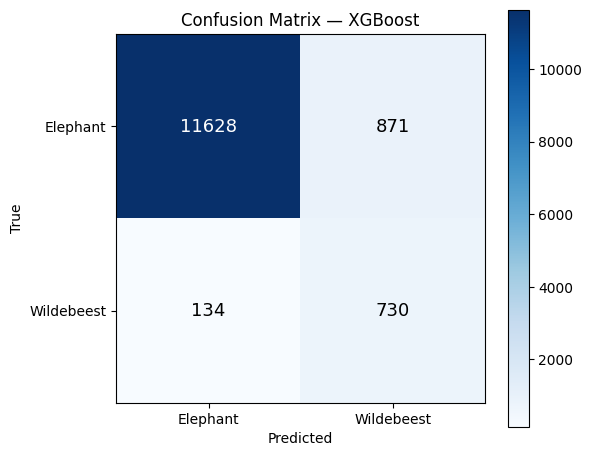

In [10]:
best_name = tbl.iloc[0]['model']
best_model = fitted[best_name]
Xte = X_test_s if best_name in NEEDS_SCALING else X_test
pred = best_model.predict(Xte)

print(f'🏆 BEST ML MODEL: {best_name}  (macro-F1 {tbl.iloc[0]["macro_f1"]:.4f})\n')
print(classification_report(y_test, pred, target_names=label_names, zero_division=0))

cm = confusion_matrix(y_test, pred)
fig, axc = plt.subplots(figsize=(6, 5))
im = axc.imshow(cm, cmap='Blues')
axc.set_xticks([0, 1]); axc.set_yticks([0, 1])
axc.set_xticklabels(label_names); axc.set_yticklabels(label_names)
axc.set_xlabel('Predicted'); axc.set_ylabel('True')
axc.set_title(f'Confusion Matrix — {best_name}')
for i in range(2):
    for j in range(2):
        axc.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=13)
plt.colorbar(im); plt.tight_layout()
plt.savefig('ml_classifier_confusion.png', dpi=150, bbox_inches='tight'); plt.show()


---
## 🌟 CELL 11: Feature Importance


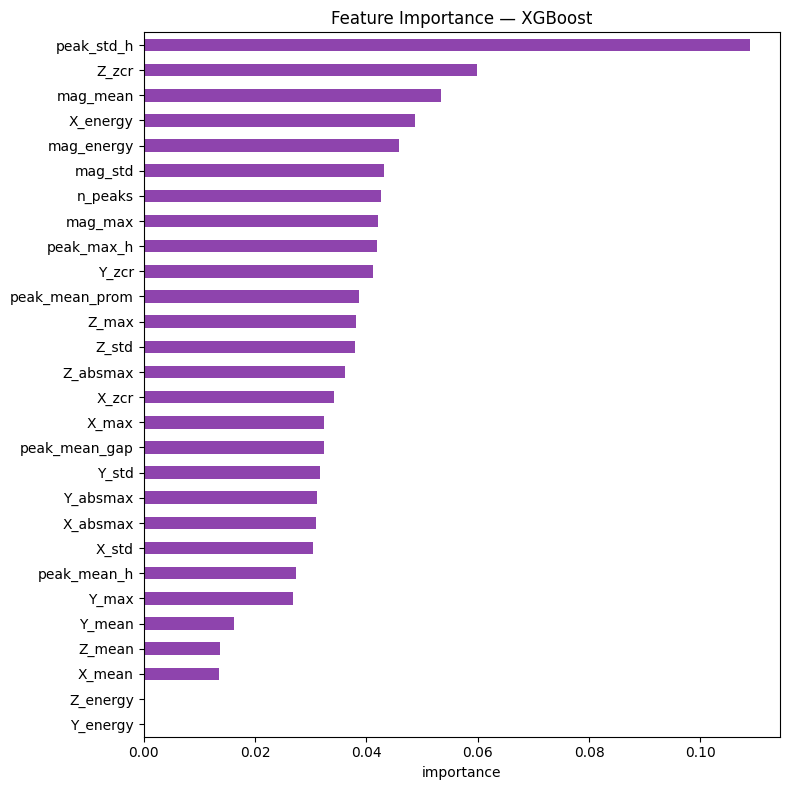

Top 8 features:
peak_std_h    0.108835
Z_zcr         0.059897
mag_mean      0.053403
X_energy      0.048816
mag_energy    0.045855
mag_std       0.043132
n_peaks       0.042706
mag_max       0.042117
dtype: float32


In [11]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=FEATURE_NAMES).sort_values()
    plt.figure(figsize=(8, 8))
    imp.plot(kind='barh', color='#8e44ad')
    plt.title(f'Feature Importance — {best_name}'); plt.xlabel('importance')
    plt.tight_layout(); plt.savefig('ml_feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()
    print('Top 8 features:'); print(imp.sort_values(ascending=False).head(8))
else:
    print(f'{best_name} has no feature_importances_ (not a tree ensemble).')


---
## 💾 CELL 12: Export Best Model


In [12]:
import joblib
joblib.dump({'model': best_model, 'scaler': scaler,
             'needs_scaling': best_name in NEEDS_SCALING,
             'feature_names': FEATURE_NAMES, 'label_names': label_names},
            'best_ml_classifier.joblib')
print('Saved -> best_ml_classifier.joblib')
print('\nInference on a new (3, 2048) recording:')
print("  b = joblib.load('best_ml_classifier.joblib')")
print("  f = extract_features(sig).reshape(1, -1)")
print("  if b['needs_scaling']: f = b['scaler'].transform(f)")
print("  pred = b['model'].predict(f)   # 0=Elephant, 1=Wildebeest")


Saved -> best_ml_classifier.joblib

Inference on a new (3, 2048) recording:
  b = joblib.load('best_ml_classifier.joblib')
  f = extract_features(sig).reshape(1, -1)
  if b['needs_scaling']: f = b['scaler'].transform(f)
  pred = b['model'].predict(f)   # 0=Elephant, 1=Wildebeest
